# Направление 3 (и косвенно направление 6) на другом масштабе задачи: настоящий ResNet-18 на CIFAR-10/100, GPU

**Контекст.** Весь проект до этого момента искал попарные причинные связи между каналами (synergy/subadditivity) в ResNet-18, предобученном на ImageNet (1000 классов, 224x224) - и почти не нашёл их ни на одной из проверенных глубин, ни в обученной, ни в необученной сети (см. `class_vs_rest_experiments/`, `architecture_ablation_experiments/`). Отдельно, на игрушечной сети (TapNet, MNIST) было показано, что главный фактор - ширина слоя в сочетании с BatchNorm+residual, а dropout делает сеть заметно более аддитивной.

**Что проверяет этот ноутбук.** Два вопроса, которые раньше проверялись только на ImageNet (настоящий ResNet) или только на MNIST (игрушечная сеть), а не на настоящем ResNet-18 на более простой задаче:

1. **Воспроизводится ли "связей почти нет" на CIFAR-10/100** (32x32, 10/100 классов) - том масштабе задачи, где раньше УЖЕ находились связи в маленьких сетях? Если да - это сильный аргумент, что дело в архитектуре (ширина+BN+residual), а не в сложности/масштабе задачи ImageNet. Если нет - значит, масштаб задачи тоже важен.
2. **Направление 3 (dropout) на настоящем ResNet-18**, а не на игрушечной аппроксимации - обучаем с нуля дважды (с dropout и без), сравниваем профиль связей.

**Методология - та же, что везде в проекте**, с учётом исправления, обсуждённого при разборе `class_vs_rest_experiments`:
- Абляция = `do(zero channel)` - зануление всей карты признаков канала.
- Причинный **S-тест (синергия/субаддитивность)** считается на **сыром логите** истинного класса: TE = baseline_logit - ablated_logit, S(A,B) = TE(A,B)-TE(A)-TE(B) (S>0 - синергия; знак исправлен после разбора в чате, раньше было перевёрнутое S=TE(A)+TE(B)-TE(A,B)). НИКАКИХ вероятностей и margin здесь нет - только так гарантированно ловятся нелинейности сети, а не нелинейности способа измерения (softmax, max() и т.п.).
- **Разметка роли канала** (critical/harmful/neutral, для сравнения контекста) считается на эпсилон (ξ) из C-SWAP - относительном изменении softmax-вероятности истинного класса. Это одноканальный тест (не попарный), поэтому нелинейность softmax здесь не создаёт ложных "взаимодействий" между парой каналов - используется только ради сравнимости с остальной частью проекта.
- FDR-BY поправка на множественность + порог эффекта tau (доля std baseline) - везде.
- Обученная сеть (несколько сидов) + необученная (случайная инициализация + калибровка BatchNorm на обычных изображениях, без обучения) - контроль, как и везде в проекте.

**Архитектурная адаптация под CIFAR (32x32 вместо 224x224) - и почему это даже интересно само по себе.** Стандартная практика для ResNet на CIFAR - заменить входной stem (conv 7x7 stride 2 + maxpool, рассчитанный на 224x224) на лёгкий conv 3x3 stride 1 без maxpool, иначе 32x32 сожмётся до 8x8 уже на входе в `layer1`. Это не просто техническая адаптация: в `architecture_ablation_experiments/FINDINGS.md` отдельно отмечалось, что тяжёлый ImageNet-stem (сам по себе BatchNorm+ReLU+maxpool) - вероятный кандидат на то, почему связи в настоящем ResNet-18 уже "мёртвы" на первой измеримой точке (`layer1`). Здесь stem намного легче - если связи всё равно окажутся на нуле, это говорит, что дело не в тяжести stem, а в чём-то внутри самих `layer1-4` (ширина+BN+residual, как и показал TapNet).

**Структура ноутбука:** данные → модель (+ dropout) → инфраструктура причинного теста (hooks, роль на ξ, S-тест на ATE) → обучение → основной цикл эксперимента → анализ и сравнение с уже известными числами по ImageNet.


## 1. Настройка окружения (Colab, GPU)

In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU - смотри PLAN.md, без GPU будет медленно")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CUDA available: True
Device: Tesla T4


In [ ]:
# Подключение Google Drive - ОБЯЗАТЕЛЬНО, чтобы не потерять результаты при разрыве сессии Colab
# (сессии Colab могут отключаться по таймауту; чекпойнты пишутся в Drive после КАЖДОЙ обученной сети)
from google.colab import drive
drive.mount('/content/drive')

import os
OUT_DIR = "/content/drive/MyDrive/cnn_mi_experiments/colab_cifar_experiment"
os.makedirs(OUT_DIR, exist_ok=True)
print("Результаты будут сохраняться в:", OUT_DIR)

Mounted at /content/drive
Результаты будут сохраняться в: /content/drive/MyDrive/cnn_mi_experiments/colab_cifar_experiment


## 2. Конфигурация - все параметры здесь, фиксируются до просмотра результатов

In [ ]:
import random
import numpy as np

SEED = 42
DATASET = "CIFAR10"          # "CIFAR10" (10 классов) или "CIFAR100" (100 классов) - поменяйте и перезапустите с этой ячейки
N_CLASSES = 10 if DATASET == "CIFAR10" else 100

EPOCHS = 30                   # для настоящего обучения; поставьте 2-3 для быстрой проверки, что всё работает
LR = 1e-3
BATCH_SIZE = 128

DROPOUT_P = 0.1               # сравниваем ровно эти два значения (направление 3)
MECHANISMS = [("no_dropout", 0.0), ("dropout", DROPOUT_P)]

N_TRAIN_SEEDS = 3             # обученных сетей на механизм
N_UNTRAIN_SEEDS = 3           # необученных (контроль) сетей на механизм

N_CAL = 128                   # калибровочных изображений на класс (как везде в проекте)
N_PAIRS = 800                 # случайных пар на слой (как в последнем ImageNet-прогоне, для сравнимости)
ALPHA = 0.05
FDR_METHOD = "fdr_by"
TAU_REL = 0.02
PROB_FLOOR = 1e-3

# те же 4 точки по глубине, что в остальном проекте (layer{1,2,3,4}.1.conv2) - для прямого
# сравнения с уже известными числами на ImageNet. Число каналов - свойство АРХИТЕКТУРЫ ResNet-18,
# не датасета, поэтому те же 64/128/256/512, что и в ImageNet-экспериментах.
LAYERS = [(0, 1, 64, "layer1.1.conv2"), (1, 1, 128, "layer2.1.conv2"),
          (2, 1, 256, "layer3.1.conv2"), (3, 1, 512, "layer4.1.conv2")]

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"DATASET={DATASET}, N_CLASSES={N_CLASSES}, EPOCHS={EPOCHS}, точек по глубине={len(LAYERS)}")

DATASET=CIFAR10, N_CLASSES=10, EPOCHS=30, точек по глубине=4


## 3. Данные

Train/sel/test разбиение, как везде в проекте: **sel - калибровочная часть, НЕ участвует в обучении** (причинный тест должен проверяться не на тех же изображениях, что видела сеть при обучении, иначе можно спутать память с обобщением).

Для обучения - аугментация (random crop + flip, стандартно для CIFAR). Для калибровки/теста - **без аугментации**, детерминированно (иначе "baseline"-логит для причинного теста не будет фиксированным от вызова к вызову).

**Загрузка через Hugging Face, не через стандартный загрузчик torchvision.** Дефолтный сервер torchvision (`cs.toronto.edu`) часто качается очень медленно из Colab. В проекте это уже решено для CIFAR-10 в `experiment_common_task.ipynb` - данные берутся с Hugging Face (`uoft-cs/cifar10`), это заметно быстрее. Здесь используется тот же приём, плюс аналогичный путь для CIFAR-100 (с проверкой и запасным вариантом через torchvision, если зеркало HF для CIFAR-100 окажется недоступно).

In [ ]:
import io
import shutil
from urllib.request import Request, urlopen

import pandas as pd
from PIL import Image
import torchvision
import torchvision.transforms as T

MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

train_transform = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                              T.ToTensor(), T.Normalize(MEAN, STD)])
eval_transform = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

def load_cifar_from_hf(hf_name, subfolder, cache_dir="./data"):
    '''Качает CIFAR-10/100 с Hugging Face (быстрее, чем стандартный cs.toronto.edu у
    torchvision) - тот же приём, что в synergy_experiments/experiment_common_task.ipynb
    для CIFAR-10. subfolder различается между датасетами ("plain_text" для cifar10,
    "cifar100" для cifar100 - проверено по структуре репозитория на HF). Возвращает
    (x_train, y_train, x_test, y_test) как numpy uint8 массивы.'''
    os.makedirs(cache_dir, exist_ok=True)
    npz_path = os.path.join(cache_dir, f"{hf_name.replace('/', '_')}_u8.npz")
    if os.path.exists(npz_path):
        z = np.load(npz_path)
        return z["x_train"], z["y_train"], z["x_test"], z["y_test"]
    base = f"https://huggingface.co/datasets/{hf_name}/resolve/main/{subfolder}/"
    out = {}
    for split, name in [("train", "train-00000-of-00001.parquet"), ("test", "test-00000-of-00001.parquet")]:
        path = os.path.join(cache_dir, f"{hf_name.replace('/', '_')}_{split}.parquet")
        if not os.path.exists(path):
            req = Request(base + name, headers={"User-Agent": "Mozilla/5.0"})
            with urlopen(req, timeout=180) as r, open(path, "wb") as f:
                shutil.copyfileobj(r, f)
        df = pd.read_parquet(path)
        label_col = "label" if "label" in df.columns else "fine_label"   # CIFAR-100: fine_label
        out[f"x_{split}"] = np.stack([np.array(Image.open(io.BytesIO(d["bytes"])).convert("RGB")) for d in df["img"]])
        out[f"y_{split}"] = df[label_col].to_numpy(dtype=np.int64)
    np.savez(npz_path, **out)
    return out["x_train"], out["y_train"], out["x_test"], out["y_test"]

class ArrayDataset(torch.utils.data.Dataset):
    '''Оборачивает numpy-массивы изображений в интерфейс (PIL.Image, label) - совместимый
    с AugDataset/PlainDataset ниже без изменений (как если бы это был torchvision.datasets.CIFAR10).'''
    def __init__(self, x, y):
        self.x, self.y = x, y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return Image.fromarray(self.x[i]), int(self.y[i])

try:
    hf_name = "uoft-cs/cifar10" if DATASET == "CIFAR10" else "uoft-cs/cifar100"
    hf_subfolder = "plain_text" if DATASET == "CIFAR10" else "cifar100"
    x_train, y_train, x_test, y_test = load_cifar_from_hf(hf_name, hf_subfolder)
    raw_train = ArrayDataset(x_train, y_train)
    raw_test_base = ArrayDataset(x_test, y_test)
    print(f"Загружено с Hugging Face ({hf_name}): train={len(raw_train)}, test={len(raw_test_base)}")
except Exception as e:
    print(f"Зеркало Hugging Face не сработало ({e}) - откат на стандартный загрузчик torchvision (может быть медленнее).")
    CIFAR = torchvision.datasets.CIFAR10 if DATASET == "CIFAR10" else torchvision.datasets.CIFAR100
    raw_train = CIFAR(root="./data", train=True, download=True)
    raw_test_base = CIFAR(root="./data", train=False, download=True)

# 45000 train / 5000 sel (калибровка), фиксированный сид
perm = torch.randperm(len(raw_train), generator=torch.Generator().manual_seed(SEED))
train_idx, sel_idx = perm[:45000].tolist(), perm[45000:].tolist()
print(f"train={len(train_idx)}, sel={len(sel_idx)}, test={len(raw_test_base)}")

class AugDataset(torch.utils.data.Dataset):
    '''Обучающая часть - с аугментацией.'''
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, indices, transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, y = self.base[self.indices[i]]
        return self.transform(img), y

class PlainDataset(torch.utils.data.Dataset):
    '''Калибровочная/тестовая часть - без аугментации, детерминированно.'''
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, indices, transform
        self.labels = np.array([base[i][1] for i in indices])
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, y = self.base[self.indices[i]]
        return self.transform(img), y

train_ds = AugDataset(raw_train, train_idx, train_transform)
sel_ds = PlainDataset(raw_train, sel_idx, eval_transform)
test_ds = PlainDataset(raw_test_base, list(range(len(raw_test_base))), eval_transform)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2)

def calib_batch(class_idx, n, seed, model=None, require_correct=True):
    '''n случайных изображений класса class_idx из sel-части; если require_correct - только
    те, что сеть классифицирует правильно (как везде в проекте для обученной сети).'''
    cand_pos = np.where(sel_ds.labels == class_idx)[0]
    if require_correct and model is not None:
        model.eval()
        xs = torch.stack([sel_ds[i][0] for i in cand_pos]).to(device)
        with torch.no_grad():
            pred = model(xs).argmax(1).cpu().numpy()
        cand_pos = cand_pos[pred == class_idx]
    assert len(cand_pos) >= 16, f"мало примеров класса {class_idx}: {len(cand_pos)}"
    rng = np.random.default_rng(seed + class_idx)
    pick = rng.choice(cand_pos, size=min(n, len(cand_pos)), replace=False)
    return torch.stack([sel_ds[i][0] for i in pick]).to(device)

Загружено с Hugging Face (uoft-cs/cifar10): train=50000, test=10000
train=45000, sel=5000, test=10000


## 4. Модель: ResNet-18, адаптированный под CIFAR (+ опциональный dropout)

Dropout вставляется в ТУ ЖЕ точку, что и во всех экспериментах с TapNet (`architecture_ablation_experiments/`) - сразу после `conv1→bn1→ReLU`, перед `conv2` (это и есть точка абляции "a" во всём проекте). В `.eval()` dropout - identity, поэтому сам причинный тест (который всегда в `.eval()`) не меняется - dropout влияет только на то, что обучение "впечатывает" в веса.

In [ ]:
import types
import torch.nn as nn
from torchvision import models

def add_dropout_to_block(block, p):
    dropout = nn.Dropout2d(p)
    def forward(self, x):
        identity = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.dropout(out)          # точка 'a' - как во всех TapNet-экспериментах проекта
        out = self.conv2(out)
        out = self.bn2(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out = out + identity
        out = self.relu(out)
        return out
    block.dropout = dropout
    block.forward = types.MethodType(forward, block)

def build_resnet18_cifar(num_classes, dropout_p=0.0):
    model = models.resnet18(weights=None, num_classes=num_classes)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    if dropout_p > 0:
        for layer in [model.layer1, model.layer2, model.layer3, model.layer4]:
            for block in layer:
                add_dropout_to_block(block, dropout_p)
    return model.to(device)

## 5. Инфраструктура причинного теста

Код ниже - прямой перенос `synergy_experiments/resnet_layer_interactions.py` и исправленной версии `class_vs_rest_experiments/resnet_one_vs_rest_profile.py` (роль на эпсилон ξ, S-тест на сыром логите ATE). Архитектура `layer1..4` у ResNet-18 не меняется между ImageNet и CIFAR (меняется только stem) - поэтому hook-подход переносится буквально без изменений.

In [ ]:
def get_stages(model):
    return [model.layer1, model.layer2, model.layer3, model.layer4]

def capture_block_io(model, stage_idx, block_idx, x_batch):
    block = get_stages(model)[stage_idx][block_idx]
    captured = {}
    def pre_block(module, inp):
        captured["x"] = inp[0].detach()
    def pre_conv2(module, inp):
        captured["a"] = inp[0].detach()
    h1 = block.register_forward_pre_hook(pre_block)
    h2 = block.conv2.register_forward_pre_hook(pre_conv2)
    with torch.no_grad():
        logits = model(x_batch)
    h1.remove(); h2.remove()
    x_in = captured["x"]
    identity = block.downsample(x_in) if block.downsample is not None else x_in
    return captured["a"], identity, logits

def run_from(model, stage_idx, block_idx, a, identity):
    stages = get_stages(model)
    block = stages[stage_idx][block_idx]
    out = block.bn2(block.conv2(a))
    out = out + identity
    x = block.relu(out)
    for b in stages[stage_idx][block_idx + 1:]:
        idn = b.downsample(x) if b.downsample is not None else x
        out = b.relu(b.bn1(b.conv1(x)))
        out = b.bn2(b.conv2(out))
        x = b.relu(out + idn)
    for s in stages[stage_idx + 1:]:
        for b in s:
            idn = b.downsample(x) if b.downsample is not None else x
            out = b.relu(b.bn1(b.conv1(x)))
            out = b.bn2(b.conv2(out))
            x = b.relu(out + idn)
    x = model.avgpool(x)
    x = torch.flatten(x, 1)
    return model.fc(x)

def batched_variant_full_logits(model, stage_idx, block_idx, a, identity, variants, chunk=64):
    B = a.shape[0]
    out_rows = []
    with torch.no_grad():
        for start in range(0, len(variants), chunk):
            bv = variants[start:start + chunk]
            k = len(bv)
            a_rep = a.unsqueeze(0).repeat(k, 1, 1, 1, 1).clone()
            for vi, channels in enumerate(bv):
                for c in channels:
                    a_rep[vi, :, c, :, :] = 0.0
            id_rep = identity.unsqueeze(0).repeat(k, 1, 1, 1, 1)
            a_flat = a_rep.view(k * B, *a.shape[1:])
            id_flat = id_rep.reshape(k * B, *identity.shape[1:])
            logits = run_from(model, stage_idx, block_idx, a_flat, id_flat)
            out_rows.append(logits.view(k, B, -1).cpu().numpy())
    return np.concatenate(out_rows, axis=0)

def sanity_check(model, layers):
    x = next(iter(test_loader))[0][:4].to(device)
    model.eval()
    for stage_idx, block_idx, _, name in layers:
        a, identity, baseline = capture_block_io(model, stage_idx, block_idx, x)
        recon = run_from(model, stage_idx, block_idx, a, identity)
        diff = (recon - baseline).abs().max().item()
        assert diff < 1e-3, f"{name}: diff {diff} слишком большой"
        print(f"  sanity ok: {name}, max|diff|={diff:.2e}")

def softmax_np(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)
    e = np.exp(x)
    return e / np.sum(e, axis=axis, keepdims=True)

from scipy import stats
from statsmodels.stats.multitest import multipletests

def mean_test(values, tau):
    _, p = stats.ttest_1samp(values, 0.0)
    return {"ate": float(np.mean(values)), "p": float(np.nan_to_num(p, nan=1.0))}

def fdr(rows, alpha, method):
    if not rows:
        return rows
    reject, p_adj, _, _ = multipletests([r["p"] for r in rows], alpha=alpha, method=method)
    for r, ok, p in zip(rows, reject, p_adj):
        r["p_fdr"], r["significant"] = float(p), bool(ok)
    return rows

def calibrate_batchnorm(model, n_images=512, seed=SEED):
    '''У случайной сети running_mean=0/var=1 - заводские заглушки. Прогоняем в .train() на
    обычных (без вмешательств) изображениях, чтобы BatchNorm получил реальные статистики этой
    конкретной случайной инициализации, затем .eval() - см. docstring в resnet_layer_interactions.py.'''
    model.train()
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(sel_ds), size=min(n_images, len(sel_ds)), replace=False)
    with torch.no_grad():
        for i in range(0, len(idx), 64):
            xb = torch.stack([sel_ds[j][0] for j in idx[i:i + 64]]).to(device)
            model(xb)
    model.eval()

In [ ]:
import itertools

def analyze_layer_one_class(model, class_idx, n_channels, stage_idx, block_idx, n_pairs, require_correct, seed=SEED):
    x = calib_batch(class_idx, N_CAL, seed, model=model if require_correct else None, require_correct=require_correct)
    a, identity, baseline_full = capture_block_io(model, stage_idx, block_idx, x)
    baseline_full_np = baseline_full.cpu().numpy()
    baseline_logit = baseline_full_np[:, class_idx]
    baseline_prob = softmax_np(baseline_full_np)[:, class_idx]
    keep = baseline_prob > PROB_FLOOR
    if not keep.all():
        a, identity = a[keep], identity[keep]
        baseline_logit, baseline_prob = baseline_logit[keep], baseline_prob[keep]
    tau_logit = TAU_REL * float(np.std(baseline_logit, ddof=1) + 1e-8)
    tau_prob = TAU_REL * float(np.std(baseline_prob, ddof=1) + 1e-8)

    single_variants = [(c,) for c in range(n_channels)]
    full_single = batched_variant_full_logits(model, stage_idx, block_idx, a, identity, single_variants)
    logit_single = full_single[:, :, class_idx]
    prob_single = softmax_np(full_single)[:, :, class_idx]
    te_single = baseline_logit[None, :] - logit_single              # для S-теста (ATE, сырой логит)
    rel_single = (prob_single - baseline_prob[None, :]) / baseline_prob[None, :]   # для роли (эпсилон)
    te_cache = {c: te_single[c] for c in range(n_channels)}

    singles = []
    for c in range(n_channels):
        r = mean_test(rel_single[c], tau_prob)
        r["channel"] = c
        singles.append(r)
    fdr(singles, ALPHA, FDR_METHOD)
    n_critical = sum(r["significant"] and abs(r["ate"]) > tau_prob and r["ate"] <= 0 for r in singles)
    n_harmful = sum(r["significant"] and abs(r["ate"]) > tau_prob and r["ate"] > 0 for r in singles)
    n_neutral = n_channels - n_critical - n_harmful

    rng = np.random.default_rng(seed + class_idx)
    pool = list(itertools.combinations(range(n_channels), 2))
    pairs = pool if len(pool) <= n_pairs else [pool[i] for i in rng.choice(len(pool), n_pairs, replace=False)]
    logit_pairs = batched_variant_full_logits(model, stage_idx, block_idx, a, identity, pairs)[:, :, class_idx]
    rows = []
    for k, (i, j) in enumerate(pairs):
        te_joint = baseline_logit[None, :] - logit_pairs[k:k + 1]
        s_vals = te_joint[0] - te_cache[i] - te_cache[j]
        r = mean_test(s_vals, tau_logit)
        r.update(a=i, b=j, S=r["ate"])
        rows.append(r)
    fdr(rows, ALPHA, FDR_METHOD)
    n_syn = sum(r["significant"] and abs(r["S"]) > tau_logit and r["S"] > 0 for r in rows)
    n_sub = sum(r["significant"] and abs(r["S"]) > tau_logit and r["S"] < 0 for r in rows)
    return {"n_critical": n_critical, "n_harmful": n_harmful, "n_neutral": n_neutral,
            "n_pairs_tested": len(rows), "total_possible_pairs": len(pool),
            "n_syn": n_syn, "n_sub": n_sub, "nonadditive_frac": (n_syn + n_sub) / max(len(rows), 1)}

def analyze_net(model, require_correct, label=""):
    rows = []
    for stage_idx, block_idx, n_channels, name in LAYERS:
        per_class = [analyze_layer_one_class(model, c, n_channels, stage_idx, block_idx, N_PAIRS, require_correct)
                     for c in range(N_CLASSES if N_CLASSES <= 10 else 10)]   # усредняем по 10 классам, как везде
        agg = {k: float(np.mean([p[k] for p in per_class])) for k in
               ["n_critical", "n_harmful", "n_neutral", "n_syn", "n_sub", "nonadditive_frac"]}
        agg["layer"] = name
        rows.append(agg)
        print(f"    [{label}] {name}: critical={agg['n_critical']:.1f}/{n_channels}, "
              f"harmful={agg['n_harmful']:.1f}/{n_channels}, нейтр.={agg['n_neutral']:.1f}/{n_channels}, "
              f"синергия={agg['n_syn']:.2f}, субадд.={agg['n_sub']:.2f}, доля неаддит.={agg['nonadditive_frac']:.3f}")
    return rows

## 6. Обучение

In [ ]:
import torch.nn.functional as F

def train_net(model, epochs, lr):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            opt.step()
        sched.step()
    return model.eval()

@torch.no_grad()
def eval_accuracy(model):
    model.eval()
    correct = total = 0
    for xb, yb in test_loader:
        xb, yb = xb.to(device), yb.to(device)
        pred = model(xb).argmax(1)
        correct += (pred == yb).sum().item()
        total += len(yb)
    return correct / total

## 7. Основной цикл эксперимента

Сетка: `{no_dropout, dropout}` x `{N_TRAIN_SEEDS обученных, N_UNTRAIN_SEEDS необученных}`. Чекпойнт (JSON) пишется в Google Drive после КАЖДОЙ сети - если сессия Colab оборвётся, прогресс не потеряется (просто перезапустите эту ячейку - уже посчитанные записи в `all_results` можно подгрузить из файла и пропустить, см. ячейку "возобновление" ниже).

In [ ]:
import json, time

RESULTS_PATH = os.path.join(OUT_DIR, f"cifar_resnet18_synergy_{DATASET}.json")

def save_checkpoint(all_results):
    with open(RESULTS_PATH, "w", encoding="utf-8") as f:
        json.dump({"config": {"DATASET": DATASET, "EPOCHS": EPOCHS, "N_CAL": N_CAL, "N_PAIRS": N_PAIRS,
                               "N_TRAIN_SEEDS": N_TRAIN_SEEDS, "N_UNTRAIN_SEEDS": N_UNTRAIN_SEEDS},
                   "results": all_results}, f, indent=2, ensure_ascii=False)

# --- возобновление после разрыва сессии: если файл уже существует, подгружаем то, что есть ---
if os.path.exists(RESULTS_PATH):
    all_results = json.load(open(RESULTS_PATH, encoding="utf-8"))["results"]
    done = {(r["mechanism"], r["net_type"], r["seed"]) for r in all_results}
    print(f"Найден чекпойнт, уже готово {len(all_results)} записей - продолжаем с того места.")
else:
    all_results = []
    done = set()

for name, dropout_p in MECHANISMS:
    for seed in range(N_TRAIN_SEEDS):
        key = (name, "обученная", seed)
        if key in done:
            continue
        t0 = time.time()
        torch.manual_seed(1000 + seed)
        model = build_resnet18_cifar(N_CLASSES, dropout_p)
        sanity_check(model, LAYERS)
        model = train_net(model, EPOCHS, LR)
        acc = eval_accuracy(model)
        print(f"=== {name} обученная seed={seed} acc={acc:.3f} ===")
        rows = analyze_net(model, require_correct=True, label=f"{name} seed={seed}")
        all_results.append({"mechanism": name, "dropout_p": dropout_p, "net_type": "обученная",
                             "seed": seed, "accuracy": acc, "rows": rows, "seconds": time.time() - t0})
        save_checkpoint(all_results)

    for seed in range(N_UNTRAIN_SEEDS):
        key = (name, "необученная", seed)
        if key in done:
            continue
        t0 = time.time()
        torch.manual_seed(2000 + seed)
        model = build_resnet18_cifar(N_CLASSES, dropout_p)
        sanity_check(model, LAYERS)
        calibrate_batchnorm(model, seed=SEED + seed)
        acc = eval_accuracy(model)
        print(f"=== {name} необученная seed={seed} acc={acc:.3f} ===")
        rows = analyze_net(model, require_correct=False, label=f"{name} seed={seed}")
        all_results.append({"mechanism": name, "dropout_p": dropout_p, "net_type": "необученная",
                             "seed": seed, "accuracy": acc, "rows": rows, "seconds": time.time() - t0})
        save_checkpoint(all_results)

print("\nГотово.", RESULTS_PATH)

  sanity ok: layer1.1.conv2, max|diff|=0.00e+00
  sanity ok: layer2.1.conv2, max|diff|=0.00e+00
  sanity ok: layer3.1.conv2, max|diff|=0.00e+00
  sanity ok: layer4.1.conv2, max|diff|=0.00e+00
=== no_dropout обученная seed=0 acc=0.919 ===
    [no_dropout seed=0] layer1.1.conv2: critical=2.3/64, harmful=0.2/64, нейтр.=61.5/64, синергия=19.50, субадд.=12.90, доля неаддит.=0.041
    [no_dropout seed=0] layer2.1.conv2: critical=3.1/128, harmful=1.6/128, нейтр.=123.3/128, синергия=0.00, субадд.=0.00, доля неаддит.=0.000
    [no_dropout seed=0] layer3.1.conv2: critical=7.0/256, harmful=6.4/256, нейтр.=242.6/256, синергия=0.00, субадд.=0.00, доля неаддит.=0.000
    [no_dropout seed=0] layer4.1.conv2: critical=4.8/512, harmful=0.8/512, нейтр.=506.4/512, синергия=0.00, субадд.=0.00, доля неаддит.=0.000
  sanity ok: layer1.1.conv2, max|diff|=0.00e+00
  sanity ok: layer2.1.conv2, max|diff|=0.00e+00
  sanity ok: layer3.1.conv2, max|diff|=0.00e+00
  sanity ok: layer4.1.conv2, max|diff|=0.00e+00
=== 

## 8. Анализ и сравнение с уже известными числами на ImageNet

Известные числа из `class_vs_rest_experiments/FINDINGS.md` (обученный ImageNet ResNet-18, класс 0, тот же протокол роль-на-ξ/S-тест-на-ATE) и из `architecture_ablation_experiments/FINDINGS.md` (TapNet) приведены ниже как константы для сравнения - заполнятся автоматически, менять не нужно.

In [ ]:
import numpy as np

results = json.load(open(RESULTS_PATH, encoding="utf-8"))["results"]

# для сравнения - числа из class_vs_rest_experiments/FINDINGS.md (ImageNet ResNet-18, класс 0, layer*.1)
IMAGENET_REFERENCE = {
    "обученная": {"layer1.1.conv2": 0.0, "layer2.1.conv2": 0.0, "layer3.1.conv2": 0.0, "layer4.1.conv2": 0.0},
    "необученная": {"layer1.1.conv2": 0.0, "layer2.1.conv2": 0.0, "layer3.1.conv2": 0.0, "layer4.1.conv2": 0.013},
}

print(f"{'механизм':15s} {'тип сети':12s}", *[f"{l[3]:>16s}" for l in LAYERS])
for name, _ in MECHANISMS:
    for net_type in ["обученная", "необученная"]:
        entries = [r for r in results if r["mechanism"] == name and r["net_type"] == net_type]
        if not entries:
            continue
        fracs = np.array([[b["nonadditive_frac"] for b in e["rows"]] for e in entries])
        mean_f = fracs.mean(axis=0)
        print(f"{name:15s} {net_type:12s}", *[f"{v:16.3f}" for v in mean_f])

print("\nImageNet (справочно, из class_vs_rest_experiments/FINDINGS.md):")
for net_type, d in IMAGENET_REFERENCE.items():
    print(f"{'':15s} {net_type:12s}", *[f"{v:16.3f}" for v in d.values()])

механизм        тип сети       layer1.1.conv2   layer2.1.conv2   layer3.1.conv2   layer4.1.conv2
no_dropout      обученная               0.042            0.000            0.000            0.000
no_dropout      необученная             0.002            0.000            0.000            0.000
dropout         обученная               0.000            0.000            0.000            0.000
dropout         необученная             0.002            0.000            0.000            0.000

ImageNet (справочно, из class_vs_rest_experiments/FINDINGS.md):
                обученная               0.000            0.000            0.000            0.000
                необученная             0.000            0.000            0.000            0.013


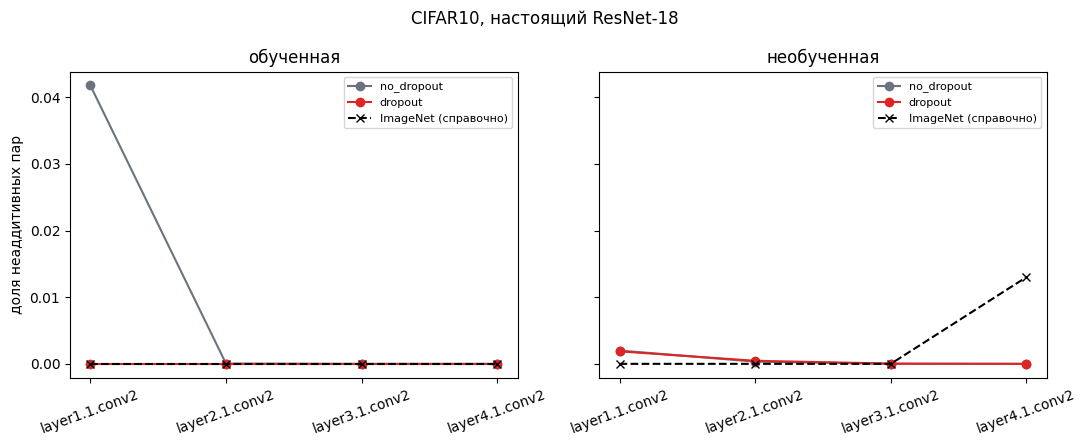

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
layer_names = [l[3] for l in LAYERS]
x = np.arange(len(layer_names))
colors = {"no_dropout": "#6b7280", "dropout": "#dc2626"}

for ax, net_type in zip(axes, ["обученная", "необученная"]):
    for name, _ in MECHANISMS:
        entries = [r for r in results if r["mechanism"] == name and r["net_type"] == net_type]
        if not entries:
            continue
        fracs = np.array([[b["nonadditive_frac"] for b in e["rows"]] for e in entries])
        ax.plot(x, fracs.mean(axis=0), marker="o", label=name, color=colors[name])
    ax.plot(x, list(IMAGENET_REFERENCE[net_type].values()), marker="x", linestyle="--",
            color="black", label="ImageNet (справочно)")
    ax.set_xticks(x); ax.set_xticklabels(layer_names, rotation=20)
    ax.set_title(net_type); ax.legend(fontsize=8)
axes[0].set_ylabel("доля неаддитивных пар")
plt.suptitle(f"{DATASET}, настоящий ResNet-18")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"cifar_resnet18_profile_{DATASET}.png"), dpi=150)
plt.show()

## 9. Что дальше

- Если на CIFAR связи ТОЖЕ почти нулевые (как на ImageNet) - сильный аргумент, что дело в архитектуре (ширина+BN+residual), а не в сложности/масштабе задачи ImageNet конкретно.
- Если на CIFAR связи ЕСТЬ (в отличие от ImageNet) - значит, масштаб/сложность задачи (или связанные с ней вещи - разрешение 32x32 против 224x224, число классов 10 против 1000) тоже имеют значение, и это стоит исследовать отдельно.
- Сравнение `no_dropout` vs `dropout` здесь - прямая проверка направления 3 на настоящей сети (не на игрушечной TapNet-аппроксимации).
- При желании - повторить с `DATASET = "CIFAR100"` (ячейка конфигурации), чтобы добавить промежуточную точку по числу классов (10 против 100 против 1000).
